In [1]:
import os
import pandas as pd
from Bio import SeqIO

# =========================
# PATHS
# =========================

proteome_dir = "../data/proteomes"

fast_dir = "../results/signalp_fast"

slow_dir = "../results/signalp_fast_slow"

# =========================
# FUNCTIONS
# =========================

def count_fasta(fasta_file):

    return sum(1 for _ in SeqIO.parse(fasta_file, "fasta"))


def count_signalp_sp(prediction_file):

    if not os.path.exists(prediction_file):
        return None

    df = pd.read_csv(
        prediction_file,
        sep="\t",
        skiprows=1
    )

    df.columns = [
        "protein_id",
        "Prediction",
        "OTHER",
        "SP",
        "CS_Position"
    ]

    return (df["Prediction"] == "SP").sum()


# =========================
# FIND SPECIES
# =========================

proteome_files = sorted([
    f for f in os.listdir(proteome_dir)
    if f.endswith(".fasta")
])

# =========================
# COLLECT STATS
# =========================

stats = []

for proteome_file in proteome_files:

    species = proteome_file.replace(".fasta", "")

    print(species)

    # -------------------------
    # Proteome size
    # -------------------------

    proteome_path = os.path.join(
        proteome_dir,
        proteome_file
    )

    proteome_count = count_fasta(proteome_path)

    # -------------------------
    # FAST SignalP
    # -------------------------

    fast_prediction = os.path.join(
        fast_dir,
        species,
        "prediction_results.txt"
    )

    fast_sp = count_signalp_sp(fast_prediction)

    # -------------------------
    # SLOW SignalP
    # -------------------------

    slow_prediction = os.path.join(
        slow_dir,
        species,
        "prediction_results.txt"
    )

    slow_sp = count_signalp_sp(slow_prediction)

    # -------------------------
    # Fractions
    # -------------------------

    fast_fraction = (
        fast_sp / proteome_count * 100
        if fast_sp is not None else None
    )

    slow_fraction = (
        slow_sp / proteome_count * 100
        if slow_sp is not None else None
    )

    # relative retention after slow validation
    retention = (
        slow_sp / fast_sp * 100
        if fast_sp and slow_sp is not None else None
    )

    stats.append({
        "species": species,
        "proteins_total": proteome_count,
        "secretome_fast": fast_sp,
        "secretome_slow": slow_sp,
        "fast_%": round(fast_fraction, 2) if fast_fraction else None,
        "slow_%": round(slow_fraction, 2) if slow_fraction else None,
        "slow_retention_%": round(retention, 2) if retention else None
    })

# =========================
# FINAL TABLE
# =========================

stats_df = pd.DataFrame(stats)

stats_df = stats_df.sort_values(
    by="proteins_total",
    ascending=False
)

stats_df

aspergillus_brasiliensis
aspergillus_clavatus
aspergillus_fumigatus
aspergillus_japonicus
aspergillus_nidulans
aspergillus_niger
aspergillus_oryzae
aspergillus_terreus
chaetomium_globosum
chaetomium_thermophilum
fusarium_graminearum
fusarium_oxysporum
myceliophthora_thermophila
neurospora_crassa
penicillium_chrysogenum
penicillium_digitatum
penicillium_funiculosum
penicillium_oxalicum
penicillium_roqueforti
pleurotus_ostreatus
podospora_anserina
rhizopus_oryzae
talaromyces_amestolkiae
talaromyces_pinophilus
thielavia_terrestris
trichoderma_atroviride
trichoderma_harzianum
trichoderma_reesei
trichoderma_virens
yarrowia_lipolytica


,species,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%
21,rhizopus_oryzae,15531,637,612,4.10,3.94,96.08
11,fusarium_oxysporum,14157,1287,1259,9.09,8.89,97.82
10,fusarium_graminearum,14147,1298,1259,9.18,8.90,97.00
5,aspergillus_niger,14069,955,913,6.79,6.49,95.60
26,trichoderma_harzianum,14049,1111,1062,7.91,7.56,95.59
6,aspergillus_oryzae,13597,799,763,5.88,5.61,95.49
0,aspergillus_brasiliensis,12982,1005,961,7.74,7.40,95.62
14,penicillium_chrysogenum,12788,856,831,6.69,6.50,97.08
28,trichoderma_virens,12389,925,892,7.47,7.20,96.43
18,penicillium_roqueforti,12315,704,683,5.72,5.55,97.02


In [2]:
stats_df.describe()

,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,11207.100000,834.933333,805.766667,7.461000,7.201000,96.476000
std,2139.121756,211.929223,206.192525,1.251047,1.228137,0.778188
min,6454.000000,434.000000,418.000000,4.100000,3.940000,95.350000
25%,9950.750000,687.500000,659.000000,6.845000,6.582500,95.700000
50%,10960.500000,804.000000,773.500000,7.470000,7.210000,96.430000
75%,12688.250000,964.750000,920.500000,7.875000,7.552500,97.015000
max,15531.000000,1298.000000,1259.000000,9.870000,9.530000,98.080000


In [3]:
stats_df.sort_values("slow_retention_%")

,species,proteins_total,secretome_fast,secretome_slow,fast_%,slow_%,slow_retention_%
3,aspergillus_japonicus,12019,968,923,8.05,7.68,95.35
17,penicillium_oxalicum,9977,660,630,6.62,6.31,95.45
1,aspergillus_clavatus,9140,682,651,7.46,7.12,95.45
6,aspergillus_oryzae,13597,799,763,5.88,5.61,95.49
26,trichoderma_harzianum,14049,1111,1062,7.91,7.56,95.59
5,aspergillus_niger,14069,955,913,6.79,6.49,95.60
2,aspergillus_fumigatus,9942,751,718,7.55,7.22,95.61
0,aspergillus_brasiliensis,12982,1005,961,7.74,7.40,95.62
15,penicillium_digitatum,9101,493,473,5.42,5.20,95.94
21,rhizopus_oryzae,15531,637,612,4.10,3.94,96.08


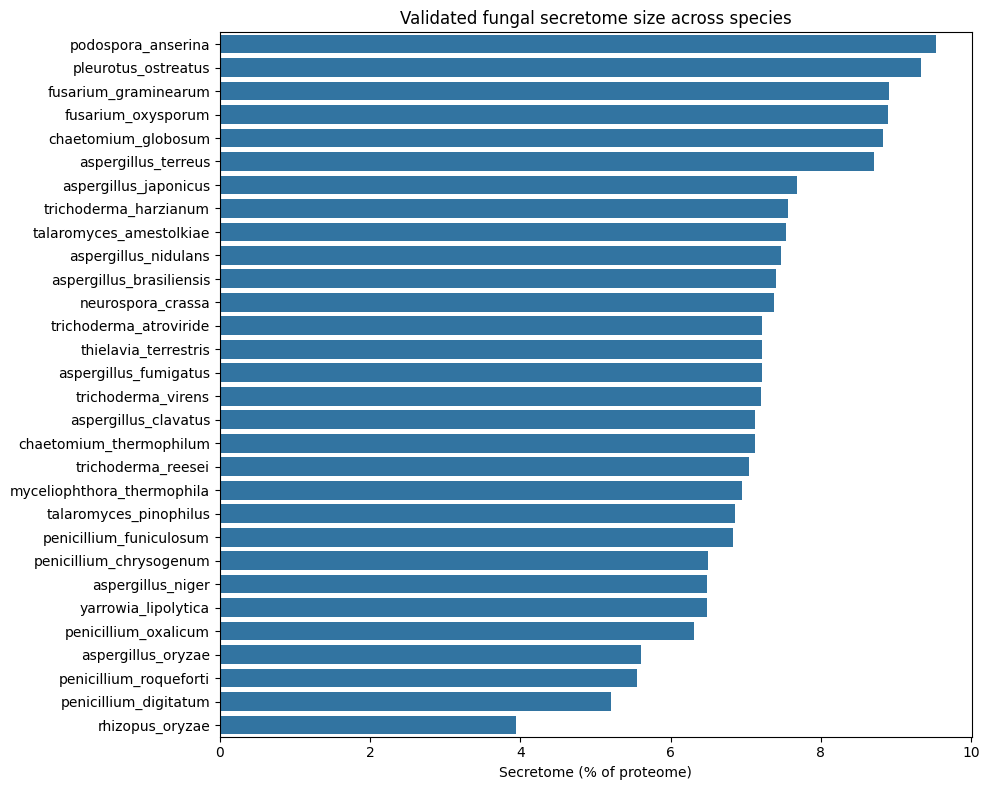

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = stats_df.sort_values("slow_%", ascending=False)

plt.figure(figsize=(10,8))

sns.barplot(
    data=plot_df,
    x="slow_%",
    y="species"
)

plt.xlabel("Secretome (% of proteome)")
plt.ylabel("")
plt.title("Validated fungal secretome size across species")

plt.tight_layout()

plt.savefig(
    "../results/figures/secretome_fraction_across_species.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

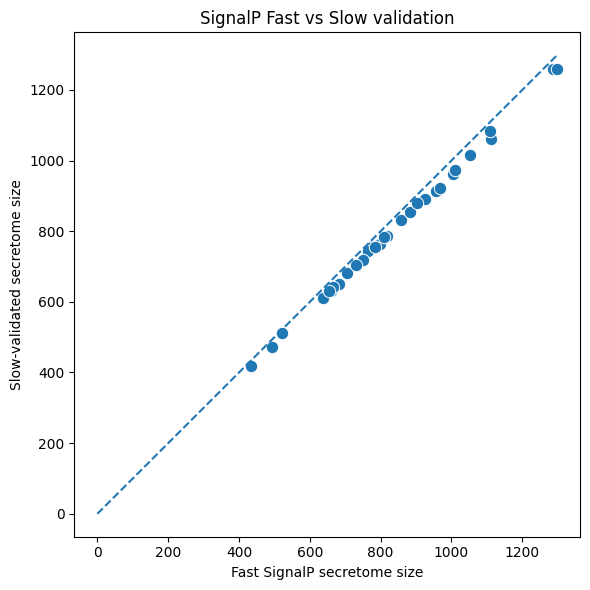

In [5]:
import numpy as np

plt.figure(figsize=(6,6))

sns.scatterplot(
    data=stats_df,
    x="secretome_fast",
    y="secretome_slow",
    s=80
)

max_val = max(
    stats_df["secretome_fast"].max(),
    stats_df["secretome_slow"].max()
)

plt.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--"
)

plt.xlabel("Fast SignalP secretome size")
plt.ylabel("Slow-validated secretome size")

plt.title("SignalP Fast vs Slow validation")

plt.tight_layout()

plt.savefig(
    "../results/figures/fast_vs_slow_signalp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()